# 06 — Kiểm tra báo nhầm ngoài tập SOS bằng DARTIS

**Phạm vi:** toàn bộ 2.290 ảnh được nhà phát hành gán no-oil: 351 ảnh bờ
và 1.939 ảnh biển. Giữ nguyên mô hình SOS, không huấn luyện lại, không đổi
ngưỡng, không loại ảnh theo kết quả. Ảnh đầu vào giữ nguyên kích thước.

Nguồn: [DARTIS, PANGAEA](https://doi.pangaea.de/10.1594/PANGAEA.980773).
Giao thức cố định trước suy luận: `results/dartis/protocol.json`.
Các cụm K-means không phải nhãn gió yếu, màng sinh học hay mưa.

Chạy từ thư mục gốc trước khi Run All notebook:
```text
python scripts/download_dartis.py --workers 1
python scripts/evaluate_dartis.py --workers 4
```
Notebook dừng nếu dữ liệu chưa đủ hoặc bằng chứng không còn khớp.
Nó không tự tải dữ liệu hoặc tự thay đổi mô hình.

In [1]:
from pathlib import Path
import sys, json
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/sar_oil').is_dir()), None)
if ROOT is None: raise RuntimeError('Open notebook inside the project')
sys.path.insert(0, str(ROOT/'scripts'))
from dartis_results import verified_results
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
result = verified_results()
print('Verified complete population:', result['completed'])
print('Frozen model SHA-256:', result['provenance']['model_sha256'])

Verified complete population: 2290
Frozen model SHA-256: cdc7b063e7bae8e8601b0c70a8277f4bb0359fcee61ac84dc022687c235d434b


## Định nghĩa phép đo

Ảnh báo nhầm: có ít nhất một vùng được mô hình giữ lại là dầu.
Tỷ lệ báo nhầm = số ảnh báo nhầm / số ảnh no-oil.
Số vùng giữ lại trên ảnh = tổng vùng dự đoán dầu / số ảnh.
Tỷ lệ pixel dầu = tổng pixel dự đoán dầu / tổng pixel đầu vào.

Đây là phép đo trên tập chỉ có mẫu âm; không báo Recall dầu hoặc F1 toàn bài.
Không dùng khoảng tin cậy giả định các patch độc lập vì có patch chung cảnh.

| Tập | Ảnh | Ảnh báo nhầm | Tỷ lệ báo nhầm | Vùng/ảnh | Pixel dầu |
|---|---:|---:|---:|---:|---:|
| Toàn bộ | 2290 | 1449 | 63.28% | 1.239 | 28.44% |
| Bờ | 351 | 337 | 96.01% | 2.422 | 58.69% |
| Biển | 1939 | 1112 | 57.35% | 1.025 | 22.96% |

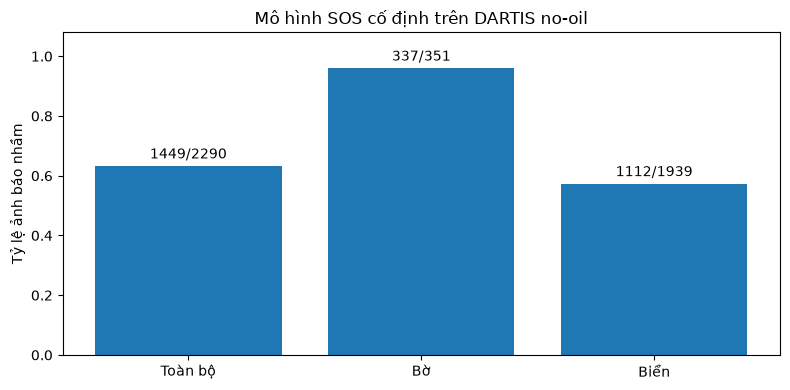

In [2]:
rows = [('Toàn bộ', result['overall']), ('Bờ', result['by_subset']['nc']), ('Biển', result['by_subset']['nw'])]
lines = ['| Tập | Ảnh | Ảnh báo nhầm | Tỷ lệ báo nhầm | Vùng/ảnh | Pixel dầu |', '|---|---:|---:|---:|---:|---:|']
for label, r in rows:
    lines.append(f"| {label} | {r['images']} | {r['false_alarm_images']} | {r['false_alarm_rate']:.2%} | {r['retained_regions_per_image']:.3f} | {r['predicted_oil_pixel_fraction']:.2%} |")
display(Markdown('\n'.join(lines)))
fig, ax = plt.subplots(figsize=(8,4))
bars = ax.bar([label for label, _ in rows], [r['false_alarm_rate'] for _, r in rows])
ax.set(ylim=(0,1.08), ylabel='Tỷ lệ ảnh báo nhầm', title='Mô hình SOS cố định trên DARTIS no-oil')
ax.bar_label(bars, labels=[f"{r['false_alarm_images']}/{r['images']}" for _, r in rows], padding=3)
plt.tight_layout(); plt.show()

## Các cụm do nhà phát hành cung cấp

Biểu đồ chỉ mô tả khác biệt giữa các nhóm K-means. Không diễn giải các cột
thành từng nguyên nhân vật lý và không dùng chúng để chọn lại mô hình.

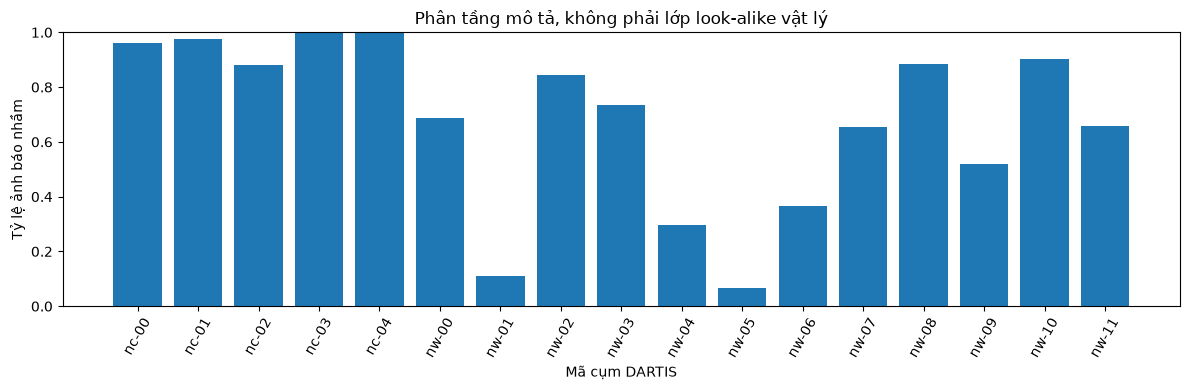

Counts per cluster: {'nc-00': 76, 'nc-01': 84, 'nc-02': 75, 'nc-03': 44, 'nc-04': 72, 'nw-00': 172, 'nw-01': 171, 'nw-02': 160, 'nw-03': 162, 'nw-04': 81, 'nw-05': 166, 'nw-06': 166, 'nw-07': 171, 'nw-08': 175, 'nw-09': 168, 'nw-10': 174, 'nw-11': 173}


In [3]:
groups = sorted(result['by_cluster'].items())
fig, ax = plt.subplots(figsize=(12,4))
ax.bar([key for key,_ in groups], [r['false_alarm_rate'] for _,r in groups])
ax.set(ylim=(0,1), ylabel='Tỷ lệ ảnh báo nhầm', xlabel='Mã cụm DARTIS', title='Phân tầng mô tả, không phải lớp look-alike vật lý')
ax.tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()
print('Counts per cluster:', {key:r['images'] for key,r in groups})

## Ba ảnh có tỷ lệ pixel báo nhầm cao nhất

Chọn cố định theo số pixel dự đoán dầu giảm dần, tên ảnh để phá hòa. Đây là
minh họa lỗi nghiêm trọng sau đánh giá, không phải mẫu ngẫu nhiên đại diện.
Chạy lại suy luận trên ba ảnh và đối chiếu số pixel/vùng với kết quả đã lưu.
Nhãn tham chiếu ở đây là no-oil mức ảnh; không có mask dầu để tính IoU.
Không dùng những ảnh này để điều chỉnh mô hình.

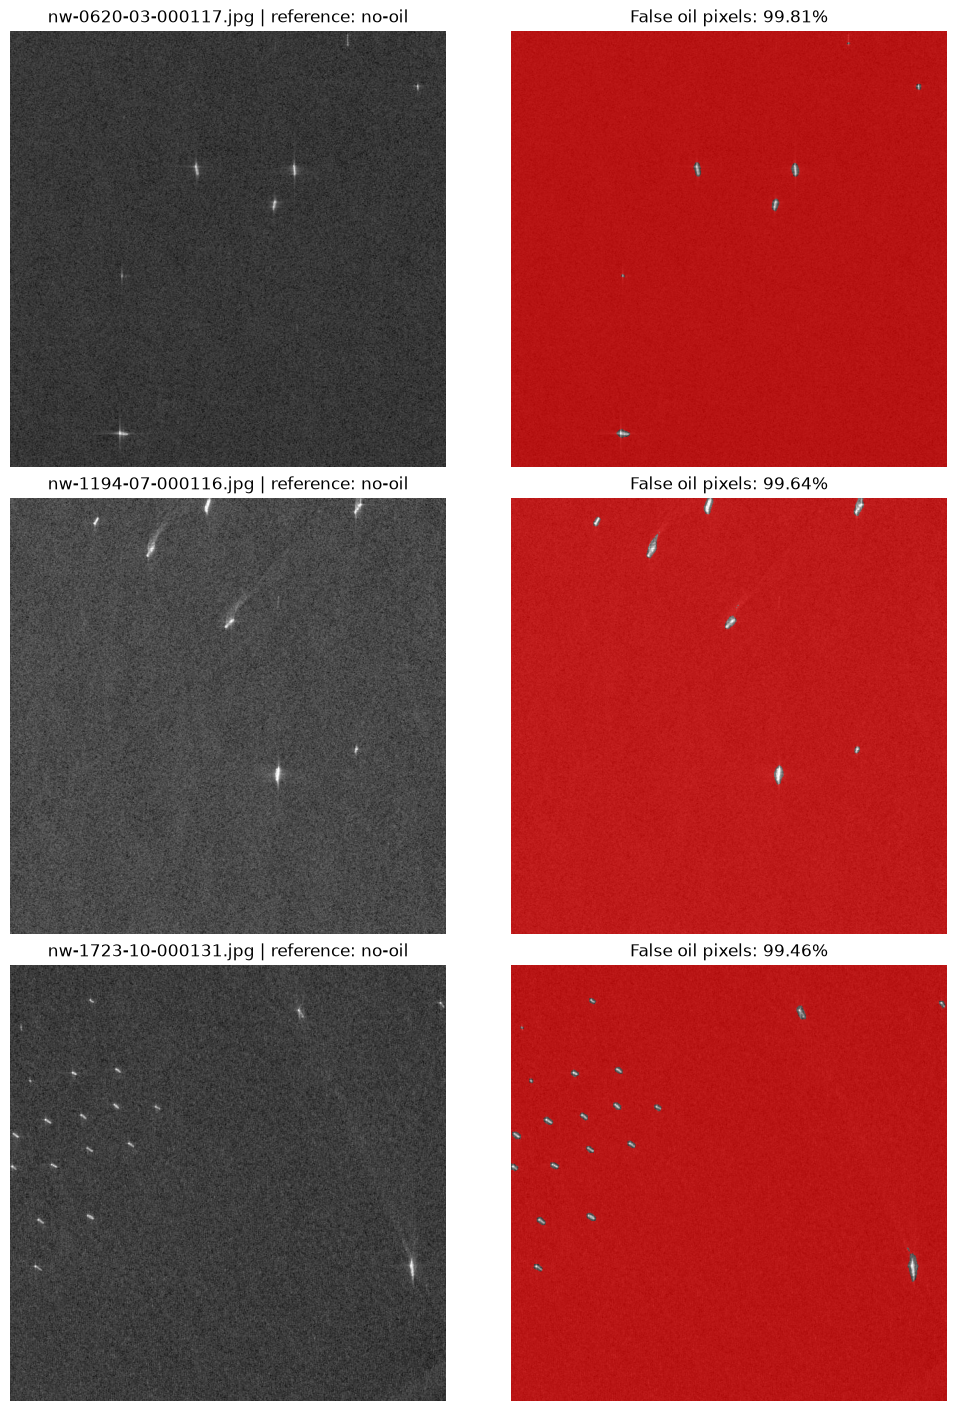

Recomputed predictions match stored pixel and region counts for all three examples.


In [4]:
import numpy as np
from PIL import Image
sys.path.insert(0, str(ROOT/'src'))
from sar_oil.models import RegionModel
from sar_oil.pipeline import predict
selected=json.loads((ROOT/'results/sos/selected.json').read_text())
model=RegionModel.load(ROOT/'results/sos'/selected['model_file'])
examples=sorted(result['per_image'], key=lambda r: (-r['predicted_oil_pixels']/r['pixels'], r['filename']))[:3]
fig,axes=plt.subplots(3,2,figsize=(10,14),layout='constrained')
for i,row in enumerate(examples):
    with Image.open(ROOT/'data/dartis'/row['filename']) as source:
        image=np.asarray(source.convert('L'),dtype=np.float64)/255.0
    mask,regions=predict(image,selected['config'],model,backend='numpy')
    assert int(mask.sum())==row['predicted_oil_pixels']
    assert sum(r['oil'] for r in regions)==row['retained_regions']
    axes[i,0].imshow(image,cmap='gray',vmin=0,vmax=1)
    axes[i,0].set_title(row['filename']+' | reference: no-oil')
    axes[i,1].imshow(image,cmap='gray',vmin=0,vmax=1)
    overlay=np.zeros((*mask.shape,4)); overlay[mask.astype(bool)]=[1,0,0,.65]
    axes[i,1].imshow(overlay)
    axes[i,1].set_title(f"False oil pixels: {mask.sum()/mask.size:.2%}")
    for ax in axes[i]: ax.set_axis_off()
plt.show()
print('Recomputed predictions match stored pixel and region counts for all three examples.')

## Giới hạn và cách dùng trong báo cáo

- Kết quả kiểm tra chuyển miền từ PNG SOS sang JPEG DARTIS khác độ phân giải,
  độ tương phản và tiền xử lý; không quy lỗi hoàn toàn cho một yếu tố.
- Nhãn no-oil là nhãn tham chiếu của bộ dữ liệu, không phải xác nhận hiện trường
  riêng của nhóm. Phép đo này chưa thay thế ma trận nhầm lẫn từng loại look-alike.
- Mọi kết quả từng ảnh, hash và số vùng được giữ trong `results/dartis/evaluation.json`.
- Không trộn tỷ lệ báo nhầm ảnh của DARTIS với Precision/Recall/F1 đối tượng SOS.
